In [3]:
!mamba install pandas

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, scikit-learn, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 0.546 seconds
  Name    Version  Build                Channel
-------------------------------------------------------------
+ pandas  3.1.0    np23py313h124dbc7_0  emscripten-forge-4x


In [4]:
!mamba install seaborn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, scikit-learn, pandas, seaborn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 0.481 seconds
  Name          Version  Build                Channel
-------------------------------------------------------------------
+ patsy         1.0.3    py313h1804a44_0      emscripten-forge-4x
+ seaborn       0.13.2   hd8ed1ab_3           conda-forge
+ seaborn-base  0.13.2   pyhd8ed1ab_3         conda-forge
+ six           1.17.0   pyhe01879c_1         conda-forge
+ statsmodels   0.15.0   np23py313h07ed413_0  emscripten-forge-4x


In [5]:
!mamba install scikit-learn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, scikit-learn, pandas, seaborn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 0.491 seconds
All requested packages already installed.


In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# loading data
regression_df = pd.read_csv("regression_data.csv", parse_dates=["hour_local"])
target = "avg_departure_delay"
core_features = regression_df.columns.drop(["hour_local", target]).tolist()

print(f"Loaded {len(regression_df):,} rows and {len(core_features)} predictors.")
regression_df[target].describe().round(2)

Loaded 28,499 rows and 23 predictors.


count    28499.00
mean        14.52
std         28.69
min        -21.00
25%          1.10
50%          7.64
75%         18.47
max       1452.00
Name: avg_departure_delay, dtype: float64

In [7]:
# Sort our data by date and time
data = regression_df.sort_values("hour_local")

# X contains the features we use to make predictions
X = data[core_features]

# y contains the variable we want to predict
y = data["avg_departure_delay"]

In [8]:
# Sort data chronologically
data = regression_df.sort_values("hour_local")

X = data[core_features]
y = data["avg_departure_delay"]

In [9]:
# Define split points
train_end = int(len(X) * 0.70)
val_end = int(len(X) * 0.85)

# Training data
X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]

# Validation data
X_val = X.iloc[train_end:val_end]
y_val = y.iloc[train_end:val_end]

# Testing data
X_test = X.iloc[val_end:]
y_test = y.iloc[val_end:]

print("Training rows (70%):", len(X_train))
print("Validation rows (15%):", len(X_val))
print("Testing rows (15%):", len(X_test))

Training rows (70%): 19949
Validation rows (15%): 4275
Testing rows (15%): 4275


In [10]:
import numpy as np
import seaborn as sns
from sklearn.metrics import r2_score
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor

In [14]:
# scaling data (the scaler only learns from the training data)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_val_scaled = scaler.transform(X_val)

In [15]:
#Baseline model- predicts the median delay of the training data
baseline = DummyRegressor(strategy="median")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_val)

print("Baseline r2:", r2_score(y_val, baseline_predictions))
print("Baseline RMSE:", root_mean_squared_error(y_val, baseline_predictions))
print("Baseline MAE:", mean_absolute_error(y_val, baseline_predictions))

Baseline r2: -0.020898060290416742
Baseline RMSE: 24.315175031695077
Baseline MAE: 11.753015513515354


In [16]:
# trying LASSO with different alpha values (LASSO picks its own features, so no RFE is needed)
alphas = np.logspace(-3, np.log10(5), 40)
r2_scores = []
n_features = []
coefficient_path = []

for alpha in alphas:
  lasso_model = Lasso(alpha=alpha, max_iter=50000)
  lasso_model.fit(X_train_scaled, y_train)

  # using the validation data to make predictions
  predictions = lasso_model.predict(X_val_scaled)

  # seeing how well the model performs on the validation data
  r2 = r2_score(y_val, predictions)
  kept = int((lasso_model.coef_ != 0).sum())

  r2_scores.append(r2)
  n_features.append(kept)
  coefficient_path.append(lasso_model.coef_)

  # printing the results for our reference
  print(f"alpha {alpha:.4f}: {kept} features, r2 is {r2}")

alpha 0.0010: 23 features, r2 is 0.07385154245965364
alpha 0.0012: 23 features, r2 is 0.07384891599004018
alpha 0.0015: 23 features, r2 is 0.07384552796629629
alpha 0.0019: 22 features, r2 is 0.07384668492380275
alpha 0.0024: 22 features, r2 is 0.07386428252069832
alpha 0.0030: 22 features, r2 is 0.07388585015875526
alpha 0.0037: 22 features, r2 is 0.07391218412757117
alpha 0.0046: 22 features, r2 is 0.07394417721756286
alpha 0.0057: 22 features, r2 is 0.07398279376818673
alpha 0.0071: 22 features, r2 is 0.07402898322522689
alpha 0.0089: 22 features, r2 is 0.07408359817014065
alpha 0.0110: 22 features, r2 is 0.07414712639852439
alpha 0.0137: 22 features, r2 is 0.07421933922072177
alpha 0.0171: 22 features, r2 is 0.0742986131930704
alpha 0.0213: 22 features, r2 is 0.07438089813394799
alpha 0.0265: 22 features, r2 is 0.07445799569436506
alpha 0.0329: 22 features, r2 is 0.07451481735599508
alpha 0.0410: 21 features, r2 is 0.07451758948707432
alpha 0.0510: 21 features, r2 is 0.074391492721

In [17]:
best_index = np.argmax(r2_scores)
best_alpha = alphas[best_index]

print("Best alpha:", best_alpha)
print("Best validation r2:", r2_scores[best_index])
print("Number of features kept:", n_features[best_index])

#Find the features LASSO kept and the ones it set to zero
best_coefficients = pd.Series(coefficient_path[best_index], index=core_features)
selected_features = best_coefficients[best_coefficients != 0].index
dropped_features = best_coefficients[best_coefficients == 0].index

print("Kept:", list(selected_features))
print("Dropped:", list(dropped_features))

Best alpha: 0.1889249141051478
Best validation r2: 0.07530169283988508
Number of features kept: 16
Kept: ['origins', 'avg_distance', 'wind_max_ms', 'visibility_min_m', 'dew_point_spread_c', 'freezing_deficit_c', 'high_wind', 'traffic_low_visibility', 'hour_sin', 'hour_cos', 'season_sin', 'season_cos', 'dow_tue', 'dow_wed', 'dow_fri', 'dow_sun']
Dropped: ['scheduled_flights', 'airlines', 'avg_scheduled_flight_time', 'temperature_c', 'low_visibility', 'dow_thu', 'dow_sat']


In [19]:
best_lasso = Lasso(alpha=best_alpha, max_iter=50000)
best_lasso.fit(X_train_scaled, y_train)

# test
lasso_predictions = best_lasso.predict(X_test_scaled)
r2 = r2_score(y_test, lasso_predictions)
rmse = root_mean_squared_error(y_test, lasso_predictions)
mae = mean_absolute_error(y_test, lasso_predictions)
print(f"r2: {r2}")
print(f"RMSE: {rmse}")
print(f"MAE: {mae}")

r2: 0.07216021888462898
RMSE: 41.016975638834175
MAE: 15.699366411461575


In [20]:
# comparing against the baseline and plain linear regression (OLS) on the same test data
ols = LinearRegression()
ols.fit(X_train_scaled, y_train)
ols_predictions = ols.predict(X_test_scaled)
baseline_test_predictions = baseline.predict(X_test)

comparison = pd.DataFrame({
    "Model": ["Baseline (median)", "OLS (23 features)", f"LASSO ({len(selected_features)} features)"],
    "r2": [r2_score(y_test, baseline_test_predictions), r2_score(y_test, ols_predictions), r2],
    "RMSE": [root_mean_squared_error(y_test, baseline_test_predictions), root_mean_squared_error(y_test, ols_predictions), rmse],
    "MAE": [mean_absolute_error(y_test, baseline_test_predictions), mean_absolute_error(y_test, ols_predictions), mae],
})
comparison

,Model,r2,RMSE,MAE
0,Baseline (median),-0.059364,43.827807,16.367905
1,OLS (23 features),0.076767,40.915020,15.833026
2,LASSO (16 features),0.072160,41.016976,15.699366


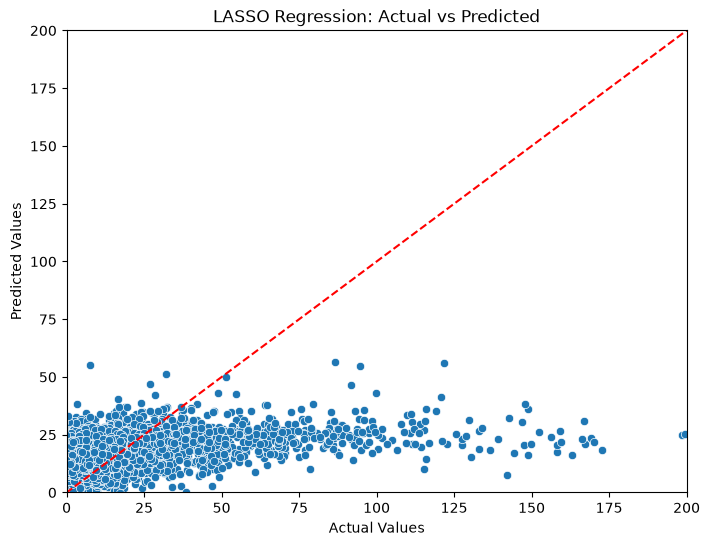

In [21]:
# plotting
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=lasso_predictions)

# perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--'
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("LASSO Regression: Actual vs Predicted")
plt.xlim(0, 200)
plt.ylim(0, 200)
plt.show()

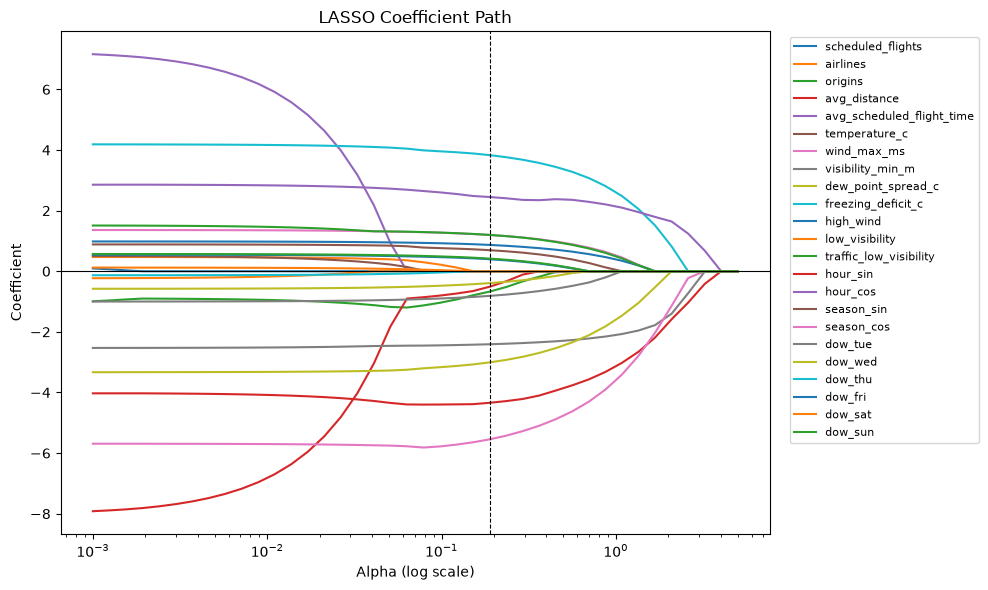

In [22]:
# plot how each coefficient shrinks as alpha increases
coefficient_path_df = pd.DataFrame(coefficient_path, index=alphas, columns=core_features)

plt.figure(figsize=(10, 6))
for feature in core_features:
    plt.plot(coefficient_path_df.index, coefficient_path_df[feature], label=feature)

plt.axvline(best_alpha, color='black', linestyle='--', linewidth=0.8)
plt.axhline(0, color='black', linewidth=0.8)
plt.xscale("log")
plt.xlabel("Alpha (log scale)")
plt.ylabel("Coefficient")
plt.title("LASSO Coefficient Path")
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

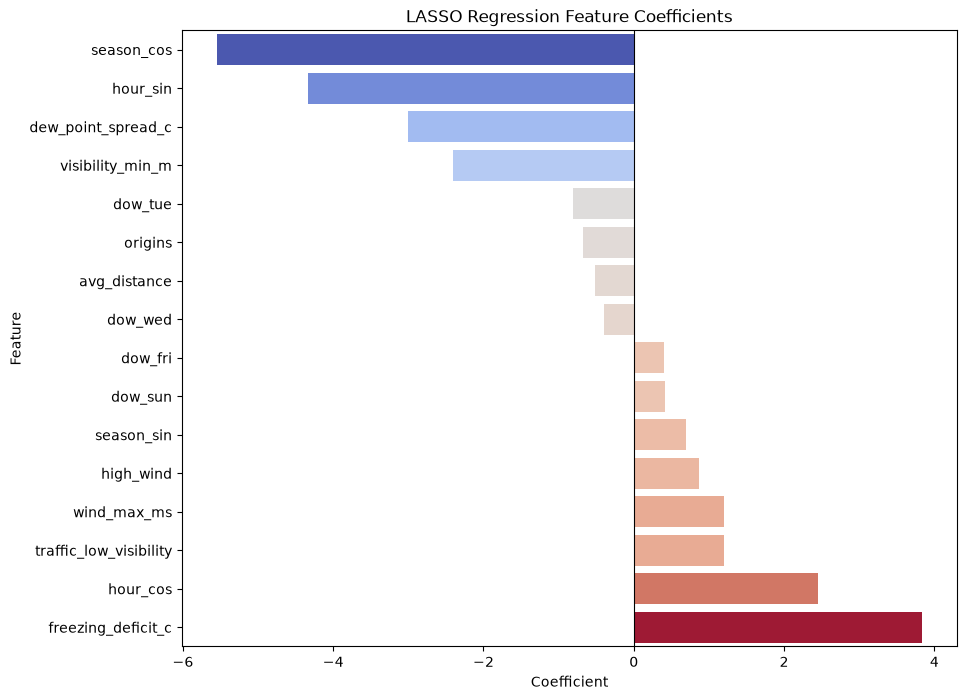

In [23]:
coefficients = best_lasso.coef_

# create dataframe (only the features LASSO kept)
coef_df = pd.DataFrame({
    'Feature': core_features,
    'Coefficient': coefficients
})
coef_df = coef_df[coef_df['Coefficient'] != 0]

# sort coefficients
coef_df = coef_df.sort_values('Coefficient')

# plot
plt.figure(figsize=(10, 8))
sns.barplot(
    data=coef_df,
    x='Coefficient',
    y='Feature',
    hue='Coefficient',
    palette='coolwarm',
    legend=False
)

plt.title("LASSO Regression Feature Coefficients")
plt.axvline(0, color='black', linewidth=0.8)
plt.show()

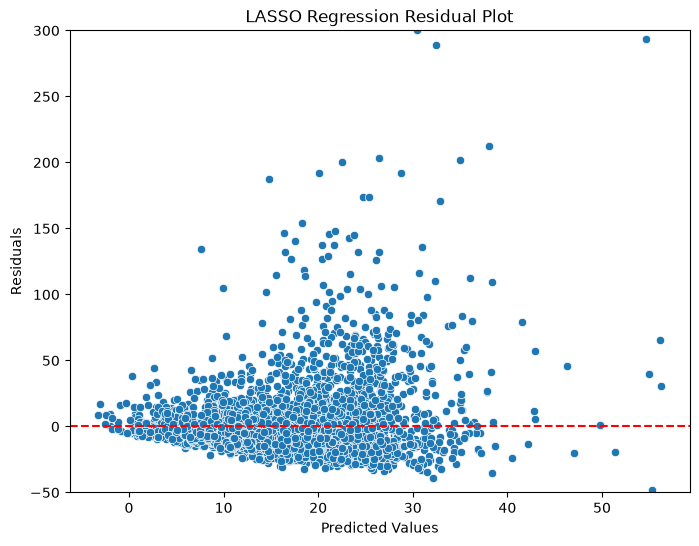

In [24]:
residuals = y_test - lasso_predictions

plt.figure(figsize=(8, 6))
sns.scatterplot(x=lasso_predictions, y=residuals)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("LASSO Regression Residual Plot")
plt.ylim(-50, 300)
plt.show()

**Findings and Explanation**

LASSO (Least Absolute Shrinkage and Selection Operator) is linear regression with an added penalty equal to alpha * the sum of the absolute values of the coefficients. The bigger alpha is, the more the coefficients get pushed toward zero. Because the penalty uses absolute values, LASSO can push coefficients all the way to exactly zero, which removes those features from the model. This means LASSO does feature selection by itself, so unlike the ridge model I didn't need RFE, so instead - alpha
I first split data into training, validation, and test ing sections with a 70-15-15 split using iloc, so the model is always trained on earlier data and tested on later data. Next, I scaled data with StandardScaler, fitted only on the training data. Scaling matters for LASSO even more than for other models because it penalizes the size of every coefficient equally. Without scaling, a feature measured in large units would get a tiny coeff and barely be penalized while a 0/1 feature like high_wind would be penalized much more, which isn't fair. I also made a baseline model with DummyRegressor that always predicts the median delay of the training data so there is something simple to compare the real model against. 
I trained the final model with alpha = 0.189 on the training data and tested it on the testing data with:
- r2 = 0.0722
- RMSE = 41.017
- MAE = 15.699
For comparison on the same testing data, the baseline got r2 = -0.059, RMSE = 43.828, MAE = 16.368, and plain linear regression (OLS) with all 23 features got r2 = 0.0768, RMSE = 40.915, MAE = 15.833. So LASSO beats the baseline on every metric and performs about the same as OLS while using 7 fewer features. LASSO made the model simpler and easier to interpret but not more accurate.
The first plot shows actual vs. predicted delays, with the red dashed line marking perfect predictions. Most points fall in a cluster at low delays, and the model almost never predicts above about 50 minutes, even when actual delays are much higher, so it badly underpredicts the largest delays. The second plot is the coefficient path, which shows how every coefficient shrinks as alpha increases, with the dashed vertical line at the chosen alpha. The most interesting part is avg_distance and avg_scheduled_flight_time: at very small alpha they have huge opposite coefficients (about -8 and +7) that mostly cancel each other out, which happens when two features are almost identical. As alpha grows, LASSO drops avg_scheduled_flight_time and avg_distance shrinks to a small value. The last features to reach zero are hour_sin, hour_cos, visibility_min_m, season_cos, and freezing_deficit_c, so time of day, visibility, season, and freezing temperatures are the most robust predictors. The third plot shows the final coefficients. The biggest effects are season_cos (-5.55, meaning more delay in summer, since season_cos is lowest around July), hour_sin (-4.34), freezing_deficit_c (+3.83, colder below freezing means more delay), and dew_point_spread_c (-3.01, humid/foggy air means more delay). The fourth plot shows the residuals. Most points are near 0, but there's a long tail of large positive residuals, which again shows that the model underpredicts big delays.

Limitations: the r2 is low at about 0.07 so a linear model with these features explains very little of the variation in delays. LASSO minimizes squared error so it aims for the average delay which is a few huge delasy pull up (max is at 1452 minutes). That's also why its MAE is only slightly better than just predicting the median. LASSO is also linear, so it can't capture thresholds or interactions unless we engineer them, which random forests and gradient boosting can. Finally, when features are highly correlated, which one LASSO keeps can be somewhat arbitrary, so the dropped features shouldn't be read as "not important."